# Demand Pattern Atlas: 3,049 Walmart SKUs
## Comprehensive Demand Decomposition & Classification

This notebook performs a deep dive into the demand patterns of 3,049 Walmart products across 10 stores. We employ Syntetos-Boylan-Croston (SBC) classification, ABC/XYZ analysis, and STL decomposition to map the demand landscape.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss

# Setting plot style
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

### 1. Data Loading and Preparation

In [13]:
calendar = pd.read_csv('Datasets/calendar.csv')
sales = pd.read_csv('Datasets/sales_train_evaluation.csv')

# Aggregating sales by item_id (Summing across 10 stores)
d_cols = [c for c in sales.columns if c.startswith('d_')]
item_sales = sales.groupby('item_id')[d_cols].sum()
print(f"Loaded {len(item_sales)} item time series.")

Loaded 3049 item time series.


### 2. Syntetos-Boylan-Croston (SBC) Classification
We classify items based on Average Demand Interval (ADI) and Coefficient of Variation squared ($CV^2$).

C:\Users\Asir\AppData\Local\Temp\ipykernel_11592\417306723.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_results, x='sbc', palette='viridis')


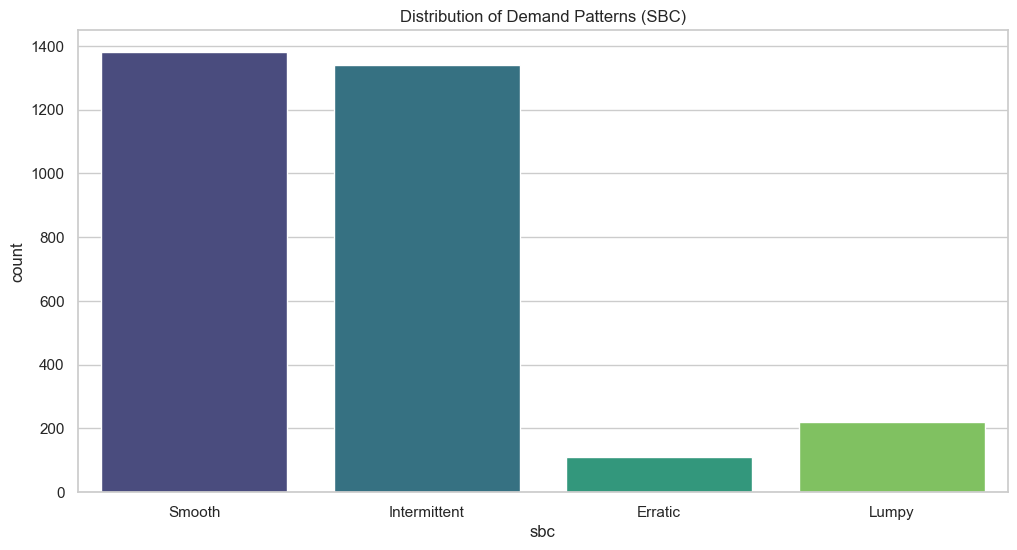

In [14]:
def classify_sbc(series):
    demand_dates = series[series > 0].index
    if len(demand_dates) <= 1: return 'Intermittent'
    adi = len(series) / len(demand_dates)
    non_zero_demand = series[series > 0]
    cv2 = (non_zero_demand.std() / non_zero_demand.mean())**2
    
    if adi < 1.32 and cv2 < 0.49: return 'Smooth'
    elif adi >= 1.32 and cv2 < 0.49: return 'Intermittent'
    elif adi < 1.32 and cv2 >= 0.49: return 'Erratic'
    else: return 'Lumpy'

results = []
for item_id, series in item_sales.iterrows():
    results.append({
        'item_id': item_id, 
        'sbc': classify_sbc(series), 
        'cv': series.std() / series.mean() if series.mean() > 0 else 0,
        'revenue': series.sum()
    })

df_results = pd.DataFrame(results)
sns.countplot(data=df_results, x='sbc', palette='viridis')
plt.title('Distribution of Demand Patterns (SBC)')
plt.show()

### 3. ABC/XYZ Analysis
Combining revenue importance (ABC) with demand variability (XYZ).

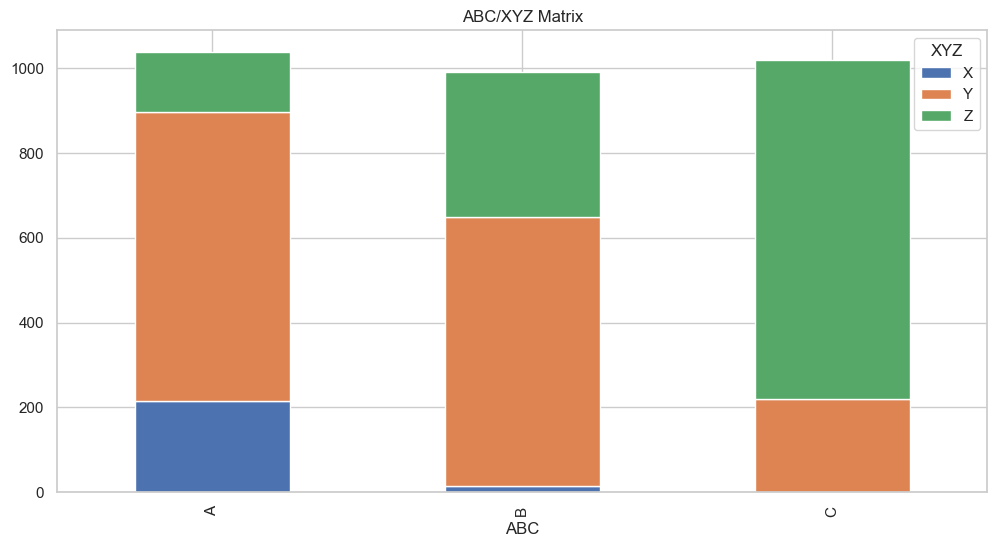

In [15]:
df_results = df_results.sort_values('revenue', ascending=False)
df_results['rev_cum_pct'] = df_results['revenue'].cumsum() / df_results['revenue'].sum()
df_results['ABC'] = pd.cut(df_results['rev_cum_pct'], bins=[0, 0.8, 0.95, 1.0], labels=['A', 'B', 'C'], include_lowest=True)
df_results['XYZ'] = pd.cut(df_results['cv'], bins=[0, 0.5, 1.0, np.inf], labels=['X', 'Y', 'Z'], include_lowest=True)

pd.crosstab(df_results['ABC'], df_results['XYZ']).plot(kind='bar', stacked=True)
plt.title('ABC/XYZ Matrix')
plt.show()

### 4. Time Series Decomposition (STL)
Visualizing the components of a 'Smooth' demand item.

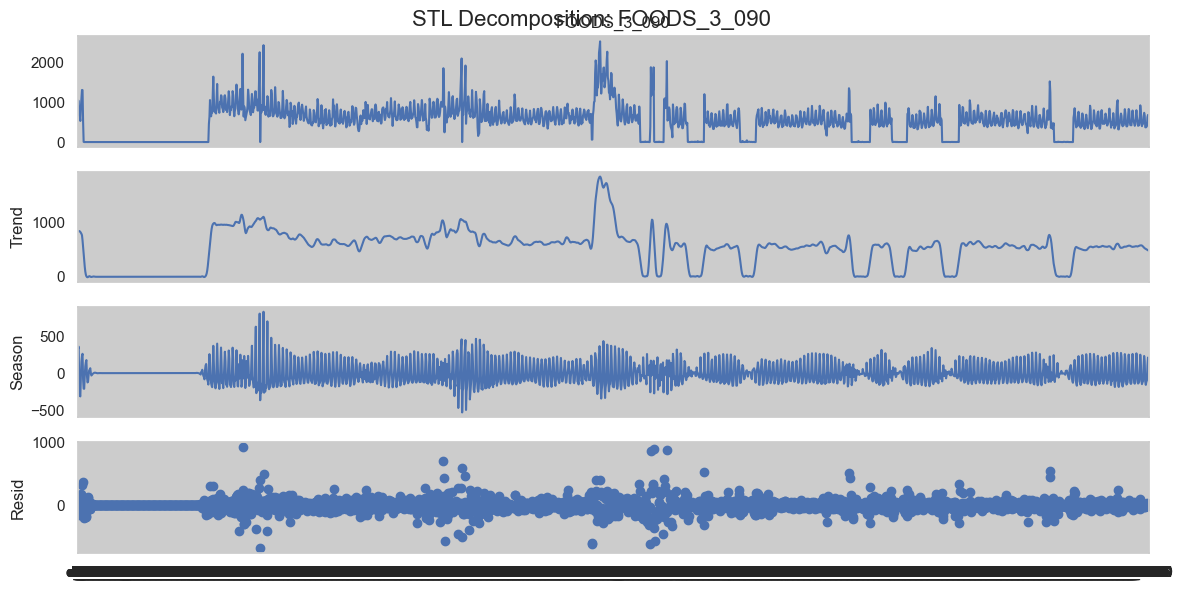

In [16]:
sample_id = df_results[df_results['sbc'] == 'Smooth'].iloc[0]['item_id']
series_sample = item_sales.loc[sample_id]
stl = STL(series_sample, period=7).fit()
stl.plot()
plt.suptitle(f'STL Decomposition: {sample_id}', fontsize=16)
plt.show()

### 5. Stationarity Tests
Using ADF and KPSS tests to verify stationarity.

In [17]:
print(f"ADF p-value: {adfuller(series_sample)[1]:.4f}")
print(f"KPSS p-value: {kpss(series_sample, regression='c')[1]:.4f}")

if adfuller(series_sample)[1] < 0.05 and kpss(series_sample, regression='c')[1] > 0.05:
    print("Series is likely Stationary.")
else:
    print("Series is likely Non-Stationary (Trend or Unit Root present).")

ADF p-value: 0.0004
KPSS p-value: 0.0448
Series is likely Non-Stationary (Trend or Unit Root present).
